<a href="https://colab.research.google.com/github/miyagi-art/simulacion2/blob/main/Integral_estocastica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

RESULTADOS DE LA SIMULACION
--------------------------------
Numero de trayectorias: 20000
Numero de intervalos: 1000

ESPERANZA
Teorica: 0.5
Simulada: 0.503035818492157
Error absoluto: 0.0030358184921569498

VARIANZA
Teorica: 0.3333333333333333
Simulada: 0.3353600471507615
Error absoluto: 0.002026713817428194


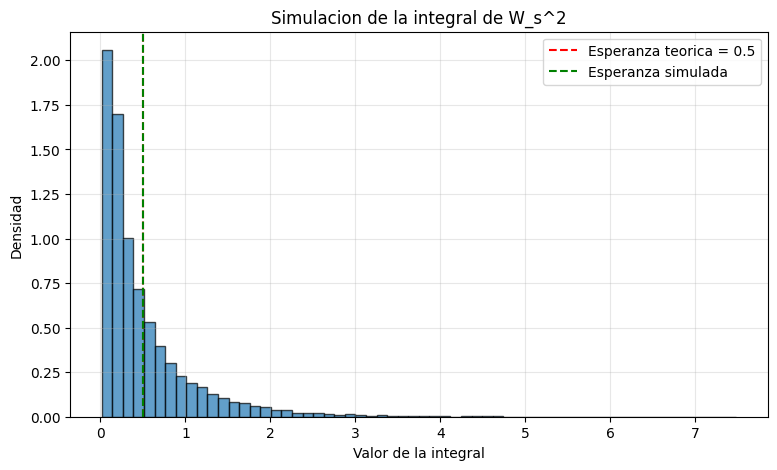

In [ ]:


import numpy as np
import matplotlib.pyplot as plt

# Parametros de simulacion
np.random.seed(2026)

t = 1
n = 1000
N = 20000

dt = t / n

# Arreglo para almacenar las integrales
resultados = []

# Simulacion de trayectorias brownianas
for inicio in range(0, N, 1000):

    m = min(1000, N - inicio)

    # Incrementos del movimiento browniano
    dW = np.sqrt(dt) * np.random.normal(0, 1, (m, n))

    # Construccion del movimiento browniano
    W = np.concatenate(
        [np.zeros((m, 1)),
         np.cumsum(dW, axis=1)],
        axis=1
    )

    # Aproximacion de la integral mediante trapecios
    integral = dt * (
        0.5 * W[:, 0]**2
        + np.sum(W[:, 1:-1]**2, axis=1)
        + 0.5 * W[:, -1]**2
    )

    resultados.extend(integral)

# Convertir a arreglo
resultados = np.array(resultados)

# Calculos estadisticos
media_simulada = np.mean(resultados)
varianza_simulada = np.var(resultados, ddof=1)

# Valores teoricos
media_teorica = t**2 / 2
varianza_teorica = t**4 / 3

# Mostrar resultados
print("RESULTADOS DE LA SIMULACION")
print("--------------------------------")
print("Numero de trayectorias:", N)
print("Numero de intervalos:", n)

print("\nESPERANZA")
print("Teorica:", media_teorica)
print("Simulada:", media_simulada)
print("Error absoluto:",
      abs(media_teorica - media_simulada))

print("\nVARIANZA")
print("Teorica:", varianza_teorica)
print("Simulada:", varianza_simulada)
print("Error absoluto:",
      abs(varianza_teorica - varianza_simulada))

# Histograma de los resultados
plt.figure(figsize=(9, 5))

plt.hist(resultados, bins=60, density=True,
         alpha=0.7, edgecolor='black')

plt.axvline(media_teorica, color='red',
            linestyle='--',
            label='Esperanza teorica = 0.5')

plt.axvline(media_simulada, color='green',
            linestyle='--',
            label='Esperanza simulada')

plt.title("Simulacion de la integral de W_s^2")
plt.xlabel("Valor de la integral")
plt.ylabel("Densidad")
plt.legend()
plt.grid(alpha=0.3)

plt.show()